# Interpretação do Modelo (Explainable AI) — Predição de Carga Alta (EVCOMX)

Segue a **Aula 08 do bootcamp** (Interpretação de Modelos; slides citados como "slide N") e vem
depois de `verificacao_validacao/`: primeiro se valida, depois se interpreta (slide 41).

**Esta etapa não escolhe nada e não muda o modelo.** O modelo explicado é o que vai para uso: a
Random Forest do plano A (`selecao_algoritmos/modelo_final_planoA.joblib`, treinada em treino +
validação). As explicações são feitas no **teste** (jun–ago/2026), que esse modelo nunca viu,
como na aula (slides 23 e 31). Olhar o teste aqui não decide nada: só descreve o que o modelo faz.

Parte do que a aula pede já estava pronto em `analise_modelos/` (seção 11d): dependência parcial
+ ICE, contribuições por caminho das árvores (Saabas) e regras para o pátio. Aqui fica o que faltava.

| Roteiro da aula (slide 42) | Seção |
|---|---|
| 1. Valide o modelo antes de interpretar | 0 |
| 2. Defina quem vai receber a explicação (slide 9) | README |
| Modelos transparentes: coeficientes da logística e regras da árvore (slides 16 a 20) | 1 |
| 3. Importância global: `feature_importances_` × permutação, colunas correlacionadas (slides 22, 23, 38) | 2 |
| 4. Forma do efeito com PDP e ICE, e os "casos impossíveis" (slides 24 a 26, 38) | 3 |
| 5. Explique casos com SHAP e LIME (slides 28 a 34) | 4 e 5 |
| Contrafactuais: o que precisaria mudar no cestão? (slide 35) | 6 |
| 6. Verifique viés e casos estranhos (slide 39) | 7 |
| 7. Traduza para a linguagem do negócio (slide 40) | 8 |

**Sem pacotes novos.** `shap` e `lime` não fazem parte do ambiente do projeto (`requirements.txt`).
Com só 6 features dá para calcular os **valores de Shapley exatos**, testando as 2⁶ = 64
combinações de colunas (é o que o `shap` faz no modo "intervencional"), e o LIME é uma regressão
linear ponderada em ~15 linhas. Ficam iguais em ideia aos pacotes, e o código mostra a conta.

**Rode antes**, em ordem: `EDA/transforma_dataset.py`, `feature_selection/feature_selection.py`,
`selecao_algoritmos/selecao_algoritmos.py`, `analise_modelos/analise_modelos.py` e
`verificacao_validacao/verificacao_validacao.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from itertools import combinations
from math import factorial
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import average_precision_score, recall_score, precision_score

SEED = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.axisbelow": True})
# mesma paleta das etapas anteriores
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"

## 0. Ler os arquivos e conferir que o modelo é o validado (slide 42, passo 1)

"Explicar um modelo ruim" é um dos erros comuns (slide 41). A `verificacao_validacao/` já conferiu o
modelo (31 conferências, nenhuma falha). Aqui só se confere que o `.joblib` carregado é o mesmo: as
chances que ele dá no teste têm de bater com as salvas pela seleção.

In [2]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "selecao_algoritmos").is_dir() and (p / "original_dataset").is_dir())
PASTA_FS = RAIZ / "feature_selection"
PASTA_SEL = RAIZ / "selecao_algoritmos"
PASTA_VV = RAIZ / "verificacao_validacao"
PASTA_SAIDA = RAIZ / "interpretacao_modelos"
PASTA_GRAF = PASTA_SAIDA / "graficos"
PASTA_GRAF.mkdir(parents=True, exist_ok=True)

def br(x, casas=2):
    """Número no formato brasileiro, para títulos e legendas: 0.425 -> '0,42'."""
    return f"{x:.{casas}f}".replace(".", ",")

def salvar(nome):
    plt.tight_layout()
    plt.savefig(PASTA_GRAF / f"{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()

for arq in ["modelo_final.json", "modelo_final_planoA.joblib", "previsoes_validacao_teste.csv"]:
    assert (PASTA_SEL / arq).exists(), f"selecao_algoritmos/{arq} não existe: rode as etapas anteriores primeiro!"
assert (PASTA_VV / "checklist_verificacao.csv").exists(), "rode verificacao_validacao/ antes: valide, depois interprete"
chk = pd.read_csv(PASTA_VV / "checklist_verificacao.csv")
print(f"Verificação: {len(chk)} conferências; resultados: {chk['resultado'].value_counts().to_dict()}")

info = json.loads((PASTA_SEL / "modelo_final.json").read_text(encoding="utf-8"))
COLS = info["plano_A"]["features"]
LIM = info["plano_A"]["limiares"]
LIM_F2 = LIM["não deixar passar (F2)"]

df = pd.read_csv(PASTA_FS / "dataset_features_completo.csv")
df["inicio"] = pd.to_datetime(df["inicio"], utc=True, format="ISO8601")
df = df.sort_values(["inicio", "cd_corrida", "nu_carregamento"]).reset_index(drop=True)
# o que o modelo final viu, montado como na seleção (treino e depois validação: a ordem das linhas muda o sorteio da floresta)
treino_val = pd.concat([df[df.conjunto == "treino"], df[df.conjunto == "validacao"]], ignore_index=True)
teste = df[df.conjunto == "teste"].reset_index(drop=True)
X_tv, y_tv = treino_val[COLS], treino_val["carga_alta"].to_numpy()
X_te, y_te = teste[COLS], teste["carga_alta"].to_numpy()

modelo = joblib.load(PASTA_SEL / "modelo_final_planoA.joblib")
assert list(modelo.features_) == COLS, "as features do .joblib não são as do modelo_final.json"
p_te = modelo.predict_proba(X_te)[:, 1]
# o .joblib é a receita do plano A re-treinada em treino + validação: refazer tem de dar o mesmo modelo
p_refeito = clone(modelo).fit(X_tv, y_tv).predict_proba(X_te)[:, 1]
assert np.allclose(p_refeito, p_te, atol=1e-9), "o .joblib não é a receita do plano A em treino + validação"
# e a mesma receita treinada só no treino reproduz as chances avaliadas na seleção
treino = df[df.conjunto == "treino"]
prev = pd.read_csv(PASTA_SEL / "previsoes_validacao_teste.csv")
prev_te = teste[["cd_corrida", "nu_carregamento"]].merge(prev[prev.conjunto == "teste"], how="left")
p_so_treino = clone(modelo).fit(treino[COLS], treino["carga_alta"]).predict_proba(X_te)[:, 1]
assert np.allclose(prev_te["prob_planoA"], p_so_treino, atol=1e-9), "a receita não reproduz as chances da seleção"
print(f"Modelo conferido: o .joblib é a receita do plano A em treino + validação, e a mesma receita só no treino\n"
      f"reproduz as chances avaliadas na seleção. Teste: {len(teste)} cestões, {y_te.sum()} cargas altas.")
print(f"PR-AUC no teste: modelo avaliado (só treino) {average_precision_score(y_te, p_so_treino):.3f} | "
      f"modelo de uso (treino + validação, o explicado aqui) {average_precision_score(y_te, p_te):.3f}")
print("Features:", COLS)

Verificação: 31 conferências; resultados: {'OK': 27, 'ATENÇÃO': 4}
Modelo conferido: o .joblib é a receita do plano A em treino + validação, e a mesma receita só no treino
reproduz as chances avaliadas na seleção. Teste: 515 cestões, 75 cargas altas.
PR-AUC no teste: modelo avaliado (só treino) 0.391 | modelo de uso (treino + validação, o explicado aqui) 0.404
Features: ['densidade_media', 'prop_peso_pesado', 'peso_por_ciclo_t', 'taxa_ca_ult5', 'taxa_ca_ult10', 'prop_PACB']


## 1. Modelos transparentes: a logística e a árvore rasa (slides 16 a 20)

A Random Forest é caixa-preta. Para ter uma "caixa de vidro" de referência, ajustamos nos mesmos
dados (treino + validação) e com as mesmas 6 features:
- uma **regressão logística com `StandardScaler`**: os coeficientes ficam em "por desvio-padrão" e
  podem ser comparados entre si (slide 17, cuidado da escala). `e^coef` é quanto a razão de chances
  (odds) é multiplicada a cada desvio-padrão a mais (slide 18);
- uma **árvore de 3 níveis**, lida como regras em texto (`export_text`, slide 20).

Cuidado das "colunas parecidas" (slide 17): `taxa_ca_ult5` × `taxa_ca_ult10` têm correlação 0,85 e
`densidade_media` × `prop_peso_pesado` 0,84. Para ver se isso deixa os coeficientes instáveis,
reajustamos a logística em 300 reamostragens por corrida (bootstrap) e contamos quantas vezes cada
coeficiente troca de sinal.

In [3]:
desv = X_tv.std()
logit = Pipeline([("vazios", SimpleImputer(strategy="median")), ("escala", StandardScaler()),
                  ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000))]).fit(X_tv, y_tv)
coef = pd.Series(logit.named_steps["modelo"].coef_[0], index=COLS)

rng = np.random.default_rng(SEED)
corridas = treino_val["cd_corrida"].unique()
idx_corrida = treino_val.groupby("cd_corrida").indices
coefs_boot = []
for _ in range(300):
    linhas = np.concatenate([idx_corrida[c] for c in rng.choice(corridas, len(corridas))])
    m = clone(logit).fit(X_tv.iloc[linhas], y_tv[linhas])
    coefs_boot.append(m.named_steps["modelo"].coef_[0])
coefs_boot = pd.DataFrame(coefs_boot, columns=COLS)

tab_logit = pd.DataFrame({
    "coef (por desvio-padrão)": coef,
    "odds × por desvio-padrão (e^coef)": np.exp(coef),
    "1 desvio-padrão =": desv,
    "IC 90% do coef (bootstrap)": [f"{np.percentile(coefs_boot[c], 5):+.2f} a {np.percentile(coefs_boot[c], 95):+.2f}" for c in COLS],
    "% das reamostragens com sinal trocado": [100 * (np.sign(coefs_boot[c]) != np.sign(coef[c])).mean() for c in COLS],
}).sort_values("coef (por desvio-padrão)", key=abs, ascending=False)
tab_logit.to_csv(PASTA_SAIDA / "coeficientes_logistica.csv")
print(f"Logística (treino + validação), PR-AUC no teste = {average_precision_score(y_te, logit.predict_proba(X_te)[:, 1]):.3f}")
tab_logit.round(3)

Logística (treino + validação), PR-AUC no teste = 0.437


,coef (por desvio-padrão),odds × por desvio-padrão (e^coef),1 desvio-padrão =,IC 90% do coef (bootstrap),% das reamostragens com sinal trocado
taxa_ca_ult5,0.550,1.734,0.301,+0.39 a +0.73,0.000
prop_peso_pesado,-0.515,0.598,0.140,-0.73 a -0.30,0.000
densidade_media,-0.255,0.775,0.141,-0.48 a -0.07,2.000
prop_PACB,0.217,1.243,0.041,+0.14 a +0.30,0.000
peso_por_ciclo_t,0.165,1.180,8.492,+0.04 a +0.27,1.333
taxa_ca_ult10,0.116,1.123,0.257,-0.07 a +0.28,16.333


Coeficiente com sinal trocado em boa parte das reamostragens = **não dá para ler a direção dele
sozinho**: o crédito está sendo dividido com a coluna parecida (slide 38). Isso é esperado no par
`taxa_ca_ult5`/`taxa_ca_ult10` e no trio densidade/pesado/peso por ciclo.

In [4]:
arvore = Pipeline([("vazios", SimpleImputer(strategy="median")),
                   ("modelo", DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, class_weight="balanced",
                                                     random_state=SEED))]).fit(X_tv, y_tv)
regras_txt = export_text(arvore.named_steps["modelo"], feature_names=COLS, show_weights=False, decimals=3)
(PASTA_SAIDA / "arvore_rasa_regras.txt").write_text(
    "Árvore de 3 níveis (treino + validação, pesos balanceados). class: 1 = carga alta prevista.\n"
    f"PR-AUC no teste = {average_precision_score(y_te, arvore.predict_proba(X_te)[:, 1]):.3f} "
    f"(Random Forest: {average_precision_score(y_te, p_te):.3f})\n\n" + regras_txt, encoding="utf-8")
print(regras_txt)
print(f"PR-AUC no teste: árvore rasa {average_precision_score(y_te, arvore.predict_proba(X_te)[:, 1]):.3f} | "
      f"logística {average_precision_score(y_te, logit.predict_proba(X_te)[:, 1]):.3f} | Random Forest {average_precision_score(y_te, p_te):.3f}")

|--- densidade_media <= 0.900
|   |--- taxa_ca_ult5 <= 0.300
|   |   |--- prop_peso_pesado <= 0.200
|   |   |   |--- class: 1
|   |   |--- prop_peso_pesado >  0.200
|   |   |   |--- class: 0
|   |--- taxa_ca_ult5 >  0.300
|   |   |--- prop_peso_pesado <= 0.159
|   |   |   |--- class: 1
|   |   |--- prop_peso_pesado >  0.159
|   |   |   |--- class: 1
|--- densidade_media >  0.900
|   |--- prop_peso_pesado <= 0.375
|   |   |--- peso_por_ciclo_t <= 14.329
|   |   |   |--- class: 0
|   |   |--- peso_por_ciclo_t >  14.329
|   |   |   |--- class: 0
|   |--- prop_peso_pesado >  0.375
|   |   |--- densidade_media <= 0.930
|   |   |   |--- class: 0
|   |   |--- densidade_media >  0.930
|   |   |   |--- class: 0

PR-AUC no teste: árvore rasa 0.314 | logística 0.437 | Random Forest 0.404


## 2. Importância global: `feature_importances_` × permutação (slides 22, 23 e 38)

- **`feature_importances_`** (redução de impureza no treino): rápida, mas favorece colunas com
  muitos valores diferentes (slide 22). `prop_PACB` é zero em ~80% dos cestões e `taxa_ca_ult5` só
  tem 6 valores possíveis; as contínuas (densidade, peso por ciclo) levam vantagem.
- **Permutação no teste**, com o Pipeline inteiro (slide 23), medindo a queda da PR-AUC.
- **Permutação em grupo** (slide 38): embaralhar `taxa_ca_ult5` sozinha subestima o histórico,
  porque `taxa_ca_ult10` "cobre" a falta. Embaralhando as duas juntas (mesma permutação de linhas)
  aparece o peso real do histórico. Idem para a "receita" (densidade, pesado e peso por ciclo).
- Para comparar com a logística (exercício da aula, item 2): o módulo do coeficiente padronizado.

In [5]:
perm = permutation_importance(modelo, X_te, y_te, scoring="average_precision", n_repeats=30, random_state=SEED)
mdi = pd.Series(modelo.named_steps["modelo"].feature_importances_, index=COLS)

def permutacao_grupo(grupo, n_rep=30):
    base = average_precision_score(y_te, modelo.predict_proba(X_te)[:, 1])
    r = np.random.default_rng(SEED)
    quedas = []
    for _ in range(n_rep):
        Xp = X_te.copy()
        ordem = r.permutation(len(Xp))
        Xp[grupo] = Xp[grupo].to_numpy()[ordem]
        quedas.append(base - average_precision_score(y_te, modelo.predict_proba(Xp)[:, 1]))
    return np.mean(quedas), np.std(quedas)

GRUPOS = {"histórico (ult5 + ult10)": ["taxa_ca_ult5", "taxa_ca_ult10"],
          "receita (densidade + pesado + peso/ciclo + PACB)": ["densidade_media", "prop_peso_pesado", "peso_por_ciclo_t", "prop_PACB"]}
tab_grupo = pd.DataFrame({g: dict(zip(["queda PR-AUC (média)", "desvio"], permutacao_grupo(c))) for g, c in GRUPOS.items()}).T
for g, c in GRUPOS.items():
    tab_grupo.loc[g, "soma das quedas individuais"] = perm.importances_mean[[COLS.index(x) for x in c]].sum()
print("Permutação em grupo (teste):")
print(tab_grupo.round(3).to_string())

tab_imp = pd.DataFrame({"feature_importances_ (impureza, treino)": mdi,
                        "permutação no teste (queda PR-AUC)": perm.importances_mean,
                        "permutação: desvio": perm.importances_std,
                        "|coef| logística padronizada": coef.abs(),
                        "valores distintos no treino": X_tv.nunique()})
tab_imp["posição: impureza"] = tab_imp.iloc[:, 0].rank(ascending=False).astype(int)
tab_imp["posição: permutação"] = tab_imp.iloc[:, 1].rank(ascending=False).astype(int)
tab_imp["posição: logística"] = tab_imp.iloc[:, 3].rank(ascending=False).astype(int)
tab_imp.round(4)

Permutação em grupo (teste):
                                                  queda PR-AUC (média)  desvio  soma das quedas individuais
histórico (ult5 + ult10)                                         0.209   0.018                        0.170
receita (densidade + pesado + peso/ciclo + PACB)                 0.086   0.036                        0.069


,"feature_importances_ (impureza, treino)",permutação no teste (queda PR-AUC),permutação: desvio,|coef| logística padronizada,valores distintos no treino,posição: impureza,posição: permutação,posição: logística
densidade_media,0.2721,0.0321,0.0162,0.2553,2986,2,3,3
prop_peso_pesado,0.2730,0.0110,0.0352,0.5146,2866,1,5,2
peso_por_ciclo_t,0.1948,0.0210,0.0271,0.1653,2501,3,4,5
taxa_ca_ult5,0.1056,0.1187,0.0273,0.5503,6,5,1,1
taxa_ca_ult10,0.1113,0.0513,0.0253,0.1161,11,4,2,6
prop_PACB,0.0432,0.0052,0.0042,0.2172,501,6,6,4


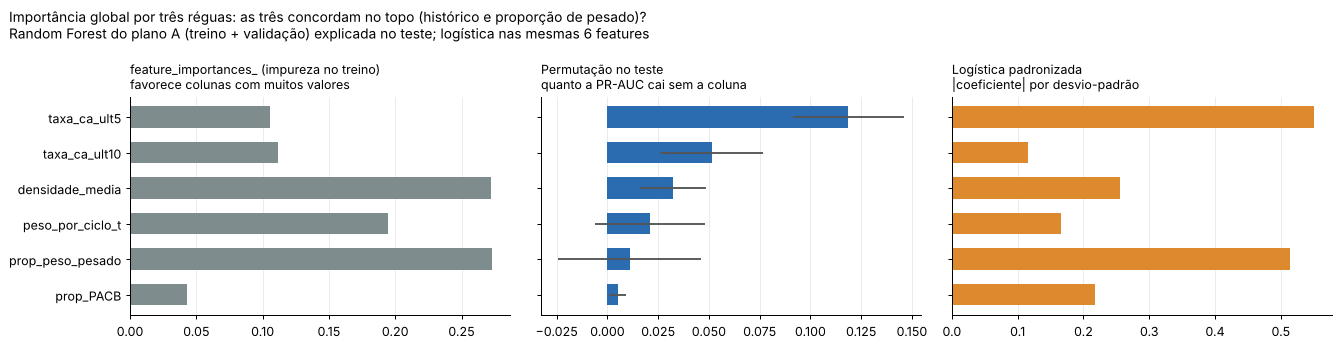

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
ordem = tab_imp.sort_values("permutação no teste (queda PR-AUC)").index
for ax, col, cor, tit in [
        (axes[0], "feature_importances_ (impureza, treino)", CINZA, "feature_importances_ (impureza no treino)\nfavorece colunas com muitos valores"),
        (axes[1], "permutação no teste (queda PR-AUC)", AZUL, "Permutação no teste\nquanto a PR-AUC cai sem a coluna"),
        (axes[2], "|coef| logística padronizada", LARANJA, "Logística padronizada\n|coeficiente| por desvio-padrão")]:
    v = tab_imp.loc[ordem, col]
    ax.barh(range(len(v)), v.values, color=cor, height=0.6,
            xerr=tab_imp.loc[ordem, "permutação: desvio"].values if "permutação" in col else None, ecolor="#555")
    ax.set_yticks(range(len(v)), ordem)
    ax.set_title(tit, loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle("Importância global por três réguas: as três concordam no topo (histórico e proporção de pesado)?\n"
             "Random Forest do plano A (treino + validação) explicada no teste; logística nas mesmas 6 features",
             x=0.01, ha="left", fontsize=11)
salvar("01_importancia_global_tres_reguas")

## 3. Forma do efeito: PDP e ICE, e os "casos impossíveis" (slides 24 a 26 e 38)

O PDP + ICE das 4 features principais já está na análise (gráfico 10 de `analise_modelos/`). Aqui ele
é refeito no **modelo final e no teste** para as duas features que mais pesam, e com a conferência
que a aula pede no slide 38: o PDP de `prop_peso_pesado` cria cestões com a proporção de pesado
trocada **mas a densidade mantida**, e essas duas colunas andam juntas (0,84). Quantos desses
cestões inventados existem de verdade? Contamos um ponto como "impossível" quando a célula dele numa
grade 10 × 10 (decis do treino) das duas colunas tem menos de 3 cestões reais.

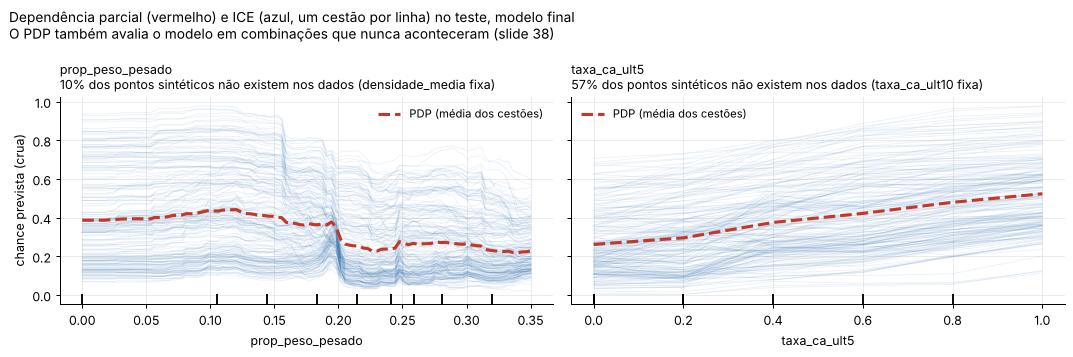

,coluna mantida,% pontos sintéticos sem cestão real parecido,PDP: chance no menor valor,PDP: chance no maior valor,ICE: % dos cestões em que a chance sobe
prop_peso_pesado,densidade_media,10.009709,0.387518,0.228597,21.941748
taxa_ca_ult5,taxa_ca_ult10,57.087379,0.262236,0.524346,100.0


In [7]:
def frac_impossivel(col_var, col_fixa, grade, X, n_min=3):
    """% dos pontos sintéticos do PDP/ICE (col_var na grade, col_fixa real) que caem em células vazias."""
    q_v = np.unique(np.nanquantile(X_tv[col_var], np.linspace(0, 1, 11)))
    q_f = np.unique(np.nanquantile(X_tv[col_fixa], np.linspace(0, 1, 11)))
    h, _, _ = np.histogram2d(X_tv[col_var].fillna(X_tv[col_var].median()), X_tv[col_fixa].fillna(X_tv[col_fixa].median()), [q_v, q_f])
    iv = np.clip(np.searchsorted(q_v, grade, side="right") - 1, 0, len(q_v) - 2)
    jf = np.clip(np.searchsorted(q_f, X[col_fixa].fillna(X_tv[col_fixa].median()).to_numpy(), side="right") - 1, 0, len(q_f) - 2)
    return 100 * (h[iv[:, None], jf[None, :]] < n_min).mean()

PARES = {"prop_peso_pesado": "densidade_media", "taxa_ca_ult5": "taxa_ca_ult10"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
disp = PartialDependenceDisplay.from_estimator(modelo, X_te, list(PARES), kind="both", subsample=200, random_state=SEED,
                                               ax=axes, ice_lines_kw={"color": AZUL, "alpha": 0.1, "lw": 0.6},
                                               pd_line_kw={"color": VERMELHO, "lw": 2.5})
tab_impossivel = {}
for ax, (c, fixa), linha in zip(axes, PARES.items(), disp.pd_results):
    grade = np.asarray(linha["grid_values"][0])
    pct = frac_impossivel(c, fixa, grade, X_te)
    ice = np.asarray(linha["individual"][0])
    tab_impossivel[c] = {"coluna mantida": fixa, "% pontos sintéticos sem cestão real parecido": pct,
                         "PDP: chance no menor valor": linha["average"][0][0], "PDP: chance no maior valor": linha["average"][0][-1],
                         "ICE: % dos cestões em que a chance sobe": 100 * (ice[:, -1] > ice[:, 0]).mean()}
    ax.set_title(f"{c}\n{br(pct, 0)}% dos pontos sintéticos não existem nos dados ({fixa} fixa)", loc="left", fontsize=10)
    ax.set_ylabel("chance prevista (crua)" if ax is axes[0] else "")
    ax.grid(True, color="#e5e5e5")
    ax.legend([ax.get_lines()[-1]], ["PDP (média dos cestões)"], frameon=False, fontsize=9)
fig.suptitle("Dependência parcial (vermelho) e ICE (azul, um cestão por linha) no teste, modelo final\n"
             "O PDP também avalia o modelo em combinações que nunca aconteceram (slide 38)", x=0.01, ha="left", fontsize=11)
salvar("02_pdp_ice_e_casos_impossiveis")
tab_impossivel = pd.DataFrame(tab_impossivel).T
tab_impossivel.to_csv(PASTA_SAIDA / "pdp_casos_impossiveis.csv")
tab_impossivel

## 4. SHAP: quanto cada coluna empurrou a chance deste cestão (slides 28 a 31)

Valor de Shapley exato, com as colunas como "jogadores" (slide 28). Para um cestão `x` e uma
combinação `S` de colunas, `v(S)` é a chance média quando as colunas de `S` ficam com os valores de
`x` e as outras vêm de cestões de referência (200 cestões sorteados do treino + validação). O valor de
cada coluna é a média ponderada do quanto `v` muda quando ela entra, em todas as 2⁵ = 32 combinações
das outras. Com isso **a conta fecha** (slide 29): chance média de referência + soma dos valores =
chance prevista do cestão. O script confere isso nos 515 cestões do teste.

É o mesmo que `shap.TreeExplainer(modelo, data=referência)` ou `shap.ExactExplainer` calculam (modo
"intervencional"). A diferença para a decomposição por caminho das árvores da análise (Saabas) é a
divisão do crédito nas interações; as duas são comparadas no fim da seção.

As chances são as **cruas** do modelo (infladas pelos pesos balanceados; a análise calibrou com Platt).
A calibração não muda a ordem dos cestões, então a explicação de "o que empurra para cima ou para
baixo" vale para as duas.

In [8]:
N_REF = 200
ref = X_tv.sample(N_REF, random_state=SEED).reset_index(drop=True)
p_ = len(COLS)
MASCARAS = [np.array([j in S for j in range(p_)]) for k in range(p_ + 1) for S in combinations(range(p_), k)]
ID_MASC = {tuple(m): i for i, m in enumerate(MASCARAS)}

def shapley_exato(X, ref=ref, lote=40):
    """Valores de Shapley exatos (intervencionais) de modelo.predict_proba[:, 1]. Devolve (base, phi[n, p])."""
    X = X.reset_index(drop=True)
    R = ref.to_numpy(dtype=float)
    base = modelo.predict_proba(ref)[:, 1].mean()
    v = np.zeros((len(X), len(MASCARAS)))
    for ini in range(0, len(X), lote):
        Xb = X.iloc[ini:ini + lote].to_numpy(dtype=float)
        blocos = []
        for m in MASCARAS:
            Z = np.repeat(R[None, :, :], len(Xb), axis=0)              # [lote, N_REF, p]
            Z[:, :, m] = Xb[:, None, m]
            blocos.append(Z.reshape(-1, p_))
        prob = modelo.predict_proba(pd.DataFrame(np.vstack(blocos), columns=COLS))[:, 1]
        v[ini:ini + len(Xb)] = prob.reshape(len(MASCARAS), len(Xb), N_REF).mean(axis=2).T
    phi = np.zeros((len(X), p_))
    for j in range(p_):
        for m in MASCARAS:
            if m[j]:
                continue
            k = m.sum()
            w = factorial(k) * factorial(p_ - k - 1) / factorial(p_)
            com = m.copy(); com[j] = True
            phi[:, j] += w * (v[:, ID_MASC[tuple(com)]] - v[:, ID_MASC[tuple(m)]])
    return base, phi

base_shap, shap_te = shapley_exato(X_te)
# a conta fecha? v(todas as colunas) = chance do cestão; v(nenhuma) = média da referência
assert np.allclose(base_shap + shap_te.sum(1), p_te, atol=1e-6), "a soma dos valores de Shapley não fecha com a chance"
print(f"Conferência OK: base {base_shap:.3f} + soma dos valores de Shapley = chance prevista, nos {len(teste)} cestões do teste")
shap_df = pd.DataFrame(shap_te, columns=COLS)
imp_shap = shap_df.abs().mean().sort_values(ascending=False)
tab_imp["SHAP médio |valor| (teste)"] = imp_shap
tab_imp["posição: SHAP"] = tab_imp["SHAP médio |valor| (teste)"].rank(ascending=False).astype(int)
tab_imp.round(4).to_csv(PASTA_SAIDA / "importancia_global.csv")
imp_shap.round(3)

Conferência OK: base 0.248 + soma dos valores de Shapley = chance prevista, nos 515 cestões do teste


prop_peso_pesado    0.079
taxa_ca_ult5        0.068
taxa_ca_ult10       0.054
densidade_media     0.043
peso_por_ciclo_t    0.033
prop_PACB           0.017
dtype: float64

**Visão geral (beeswarm, slide 30)** e **SHAP × Saabas**: a decomposição por caminho das árvores
usada na análise é recalculada aqui no mesmo modelo e nos mesmos cestões, para ver se as duas contam a
mesma história.

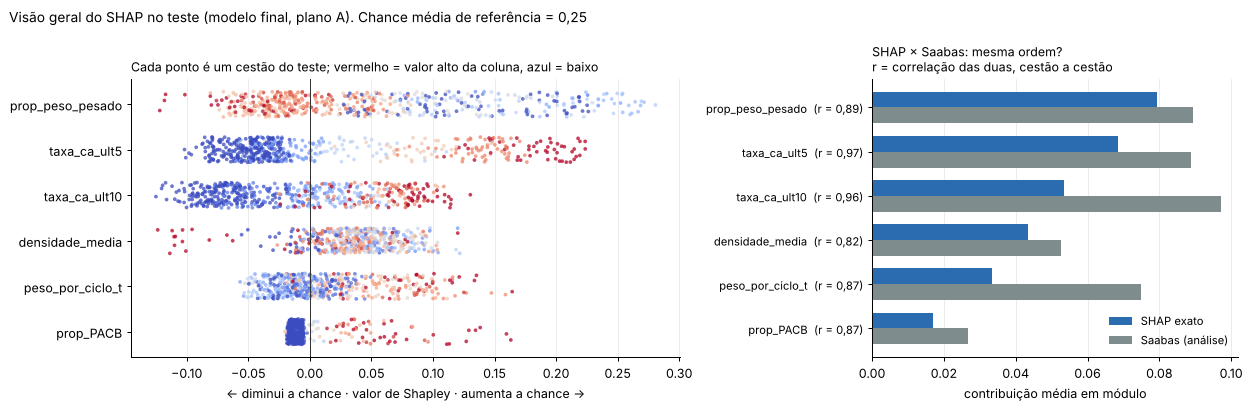

In [9]:
def saabas(pipe, X):
    """Decomposição por caminho das árvores (a mesma da análise, seção 11d)."""
    Xt = pipe.named_steps["vazios"].transform(X)
    rf = pipe.named_steps["modelo"]
    contrib, vies = np.zeros(Xt.shape), 0.0
    for est in rf.estimators_:
        t = est.tree_
        v1 = (t.value[:, 0, :] / t.value[:, 0, :].sum(axis=1, keepdims=True))[:, 1]
        caminho = est.decision_path(Xt.astype(np.float32))
        vies += v1[0]
        for i in range(Xt.shape[0]):
            nos = caminho.indices[caminho.indptr[i]:caminho.indptr[i + 1]]
            np.add.at(contrib[i], t.feature[nos[:-1]], v1[nos[1:]] - v1[nos[:-1]])
    n = len(rf.estimators_)
    return vies / n, contrib / n

_, saabas_te = saabas(modelo, X_te)
corr_metodos = pd.Series({c: np.corrcoef(shap_te[:, j], saabas_te[:, j])[0, 1] for j, c in enumerate(COLS)})
tab_imp["Saabas médio |valor| (teste)"] = np.abs(saabas_te).mean(0)
tab_imp["correlação SHAP × Saabas, cestão a cestão"] = corr_metodos
tab_imp.round(4).to_csv(PASTA_SAIDA / "importancia_global.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
r = np.random.default_rng(SEED)
ordem_s = list(imp_shap.index[::-1])
for y, c in enumerate(ordem_s):
    x = X_te[c].to_numpy()
    cor = (x - np.nanpercentile(x, 5)) / max(np.nanpercentile(x, 95) - np.nanpercentile(x, 5), 1e-9)
    ax.scatter(shap_df[c], y + r.uniform(-0.28, 0.28, len(x)), c=np.clip(np.nan_to_num(cor, nan=0.5), 0, 1),
               cmap="coolwarm", s=9, alpha=0.75, linewidths=0)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(range(len(ordem_s)), ordem_s)
ax.set_xlabel("← diminui a chance · valor de Shapley · aumenta a chance →")
ax.set_title("Cada ponto é um cestão do teste; vermelho = valor alto da coluna, azul = baixo", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
ax = axes[1]
yy = np.arange(len(ordem_s))
ax.barh(yy + 0.18, imp_shap[ordem_s].values, height=0.36, color=AZUL, label="SHAP exato")
ax.barh(yy - 0.18, tab_imp.loc[ordem_s, "Saabas médio |valor| (teste)"].values, height=0.36, color=CINZA, label="Saabas (análise)")
ax.set_yticks(yy, [f"{c}  (r = {br(corr_metodos[c])})" for c in ordem_s], fontsize=9)
ax.set_xlabel("contribuição média em módulo")
ax.set_title("SHAP × Saabas: mesma ordem?\nr = correlação das duas, cestão a cestão", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(axis="y", visible=False)
fig.suptitle(f"Visão geral do SHAP no teste (modelo final, plano A). Chance média de referência = {br(base_shap)}",
             x=0.01, ha="left", fontsize=11)
salvar("03_shap_visao_geral")

### Dois cestões explicados (slide 29 e exercício da aula, item 4)

- o cestão de **maior chance** do teste;
- um **falso negativo**: a carga alta do teste com a chance mais baixa, ou seja, a que o modelo
  "deixou passar com mais certeza". É o caso que a aula pede para explicar.

Falsos negativos no teste, no corte F2 (0,41): 21 de 75 cargas altas

maior chance: chance 0.978
                   valor   SHAP
prop_peso_pesado   0.102  0.261
taxa_ca_ult5       1.000  0.191
peso_por_ciclo_t  33.980  0.097
densidade_media    0.724  0.094
taxa_ca_ult10      0.900  0.092
prop_PACB          0.000 -0.006

falso negativo: chance 0.060
                   valor   SHAP
taxa_ca_ult10      0.000 -0.096
taxa_ca_ult5       0.000 -0.046
prop_peso_pesado   0.290 -0.024
prop_PACB          0.000 -0.014
peso_por_ciclo_t  17.033 -0.008
densidade_media    0.864 -0.001


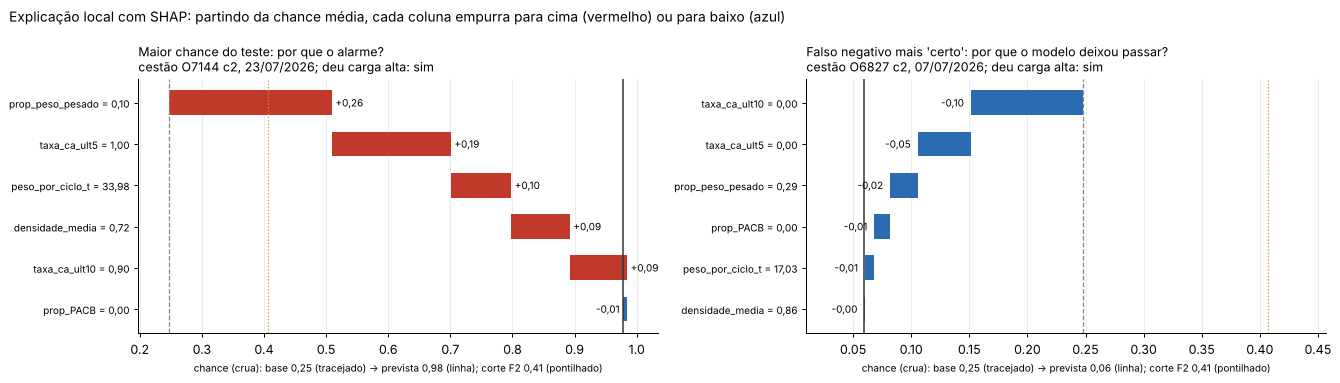

In [10]:
i_alto = int(np.argmax(p_te))
fn = np.where((y_te == 1) & (p_te < LIM_F2))[0]
i_fn = int(fn[np.argmin(p_te[fn])])
print(f"Falsos negativos no teste, no corte F2 ({br(LIM_F2)}): {len(fn)} de {y_te.sum()} cargas altas")

def waterfall(ax, i, titulo):
    v = pd.Series(shap_te[i], index=COLS)
    v = v.reindex(v.abs().sort_values().index)
    inicio = base_shap + np.concatenate([[0], np.cumsum(v.values[::-1])])[:-1][::-1]
    ax.barh(range(len(v)), v.values, left=inicio, color=[VERMELHO if x > 0 else AZUL for x in v.values], height=0.6)
    for y, (x0, dv) in enumerate(zip(inicio, v.values)):
        ax.text(x0 + dv + (0.006 if dv >= 0 else -0.006), y, f"{dv:+.2f}".replace(".", ","), va="center",
                ha="left" if dv >= 0 else "right", fontsize=8)
    ax.axvline(base_shap, color=CINZA, lw=1, ls="--")
    ax.axvline(p_te[i], color="#333", lw=1.2)
    ax.axvline(LIM_F2, color=LARANJA, lw=1, ls=":")
    ax.set_yticks(range(len(v)), [f"{c} = {br(X_te[c].iloc[i])}" for c in v.index], fontsize=8)
    pontas = np.concatenate([inicio, inicio + v.values, [LIM_F2, base_shap]])
    ax.set_xlim(pontas.min() - 0.05, pontas.max() + 0.05)
    ax.set_xlabel(f"chance (crua): base {br(base_shap)} (tracejado) → prevista {br(p_te[i])} (linha); corte F2 {br(LIM_F2)} (pontilhado)", fontsize=8)
    r_ = teste.iloc[i]
    ax.set_title(f"{titulo}\ncestão {r_.cd_corrida} c{int(r_.nu_carregamento)}, {r_.inicio.tz_convert('America/Sao_Paulo'):%d/%m/%Y}; "
                 f"deu carga alta: {'sim' if y_te[i] else 'não'}", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
waterfall(axes[0], i_alto, "Maior chance do teste: por que o alarme?")
waterfall(axes[1], i_fn, "Falso negativo mais 'certo': por que o modelo deixou passar?")
fig.suptitle("Explicação local com SHAP: partindo da chance média, cada coluna empurra para cima (vermelho) ou para baixo (azul)",
             x=0.01, ha="left", fontsize=11)
salvar("04_shap_dois_cestoes")
for nome, i in [("maior chance", i_alto), ("falso negativo", i_fn)]:
    print(f"\n{nome}: chance {p_te[i]:.3f}")
    print(pd.DataFrame({"valor": X_te.iloc[i], "SHAP": shap_te[i]}).sort_values("SHAP", key=abs, ascending=False).round(3).to_string())

## 5. LIME: um zoom na vizinhança, e o quanto ele varia (slides 32 a 34)

Para o mesmo falso negativo: geramos 1.000 cestões parecidos (ruído normal com o desvio-padrão do
treino em cada coluna, dentro dos limites observados), perguntamos ao modelo a chance de cada um e
ajustamos uma regressão linear ponderada pela distância (núcleo exponencial, largura 0,75·√p, como no
pacote `lime`). Os coeficientes, em "por desvio-padrão", são a explicação do LIME.

O slide 34 diz que o LIME "pode variar entre execuções". Repetimos com 20 sementes e medimos.

In [11]:
media_tv, desv_tv = X_tv.mean(), X_tv.std()
lo, hi = X_tv.min(), X_tv.max()

def lime_local(x, semente, n=1000, largura=0.75 * np.sqrt(len(COLS))):
    r = np.random.default_rng(semente)
    z = r.normal(0, 1, (n, len(COLS)))                       # vizinhança em desvios-padrão
    Xv = (x.to_numpy(dtype=float) + z * desv_tv.to_numpy()).clip(lo.to_numpy(), hi.to_numpy())
    Xv[0] = x.to_numpy(dtype=float)
    zs = (Xv - x.to_numpy(dtype=float)) / desv_tv.to_numpy()
    peso = np.exp(-(np.sqrt((zs ** 2).sum(1)) ** 2) / largura ** 2)
    f = modelo.predict_proba(pd.DataFrame(Xv, columns=COLS))[:, 1]
    lin = Ridge(alpha=1.0).fit(zs, f, sample_weight=peso)
    return pd.Series(lin.coef_, index=COLS)

x_fn = X_te.iloc[i_fn].fillna(X_tv.median())
lime_runs = pd.DataFrame([lime_local(x_fn, s) for s in range(20)])
top3 = lime_runs.apply(lambda r_: tuple(sorted(r_.abs().nlargest(3).index)), axis=1)
tab_lime = pd.DataFrame({
    "LIME: coef médio (por desvio-padrão)": lime_runs.mean(),
    "LIME: desvio entre 20 execuções": lime_runs.std(),
    "LIME: % execuções com sinal diferente da média": [100 * (np.sign(lime_runs[c]) != np.sign(lime_runs[c].mean())).mean() for c in COLS],
    "SHAP do mesmo cestão (exato, não varia)": shap_te[i_fn],
}).sort_values("LIME: coef médio (por desvio-padrão)", key=abs, ascending=False)
tab_lime.to_csv(PASTA_SAIDA / "lime_estabilidade.csv")
print(f"Top-3 do LIME nas 20 execuções: {top3.value_counts().to_dict()}")
tab_lime.round(3)

Top-3 do LIME nas 20 execuções: {('densidade_media', 'taxa_ca_ult10', 'taxa_ca_ult5'): 20}


,LIME: coef médio (por desvio-padrão),LIME: desvio entre 20 execuções,LIME: % execuções com sinal diferente da média,"SHAP do mesmo cestão (exato, não varia)"
taxa_ca_ult5,0.051,0.005,0.0,-0.046
taxa_ca_ult10,0.050,0.005,0.0,-0.096
densidade_media,-0.036,0.003,0.0,-0.001
peso_por_ciclo_t,-0.024,0.003,0.0,-0.008
prop_peso_pesado,-0.017,0.002,0.0,-0.024
prop_PACB,0.006,0.004,5.0,-0.014


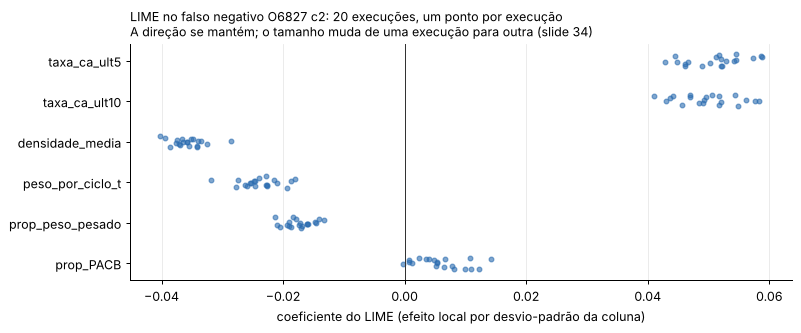

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ordem_l = list(tab_lime.index[::-1])
for y, c in enumerate(ordem_l):
    ax.scatter(lime_runs[c], np.full(len(lime_runs), y) + np.random.default_rng(y).uniform(-0.15, 0.15, len(lime_runs)),
               color=AZUL, s=14, alpha=0.6)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(range(len(ordem_l)), ordem_l)
ax.set_xlabel("coeficiente do LIME (efeito local por desvio-padrão da coluna)")
r_ = teste.iloc[i_fn]
ax.set_title(f"LIME no falso negativo {r_.cd_corrida} c{int(r_.nu_carregamento)}: 20 execuções, um ponto por execução\n"
             "A direção se mantém; o tamanho muda de uma execução para outra (slide 34)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
salvar("05_lime_estabilidade")

## 6. Contrafactuais: o que precisaria mudar no cestão? (slide 35)

Para cada cestão do teste **alarmado** no corte F2, procuramos a menor mudança que levaria a chance
para baixo do corte. Só valem mudanças **possíveis na montagem** (slide 35: "seja 10 anos mais jovem
não ajuda ninguém"): o histórico do forno (`taxa_ca_*`) não se muda na hora de montar o cestão.

Duas versões, para mostrar o cuidado do slide 38:
- **ingênua:** sobe só `prop_peso_pesado`, com a densidade parada. Combinação que pode não existir.
- **coerente:** sobe `prop_peso_pesado` e ajusta `densidade_media` e `peso_por_ciclo_t` junto, pela
  relação linear observada no treino + validação (mais pesado → cestão mais denso e mais ciclos).

Tradução: `Δ prop_peso_pesado × peso total do cestão` = toneladas de leve/misto trocadas por pesado.

In [13]:
b_dens = np.polyfit(X_tv["prop_peso_pesado"], X_tv["densidade_media"], 1)[0]
b_ciclo = np.polyfit(X_tv["prop_peso_pesado"], X_tv["peso_por_ciclo_t"], 1)[0]
print(f"No treino + validação: +0,10 de proporção de pesado ≈ {b_dens * 0.1:+.3f} t/m³ de densidade e "
      f"{b_ciclo * 0.1:+.2f} t por ciclo")
PASSOS = np.round(np.arange(0.01, 0.41, 0.01), 2)
teto_pesado = X_tv["prop_peso_pesado"].quantile(0.99)

def contrafactual(i, coerente):
    x = X_te.iloc[[i]]
    Xs = pd.concat([x] * len(PASSOS), ignore_index=True)
    Xs["prop_peso_pesado"] = x["prop_peso_pesado"].iloc[0] + PASSOS
    if coerente:
        Xs["densidade_media"] = x["densidade_media"].iloc[0] + b_dens * PASSOS
        Xs["peso_por_ciclo_t"] = np.maximum(x["peso_por_ciclo_t"].iloc[0] + b_ciclo * PASSOS, X_tv["peso_por_ciclo_t"].min())
    ok = (modelo.predict_proba(Xs)[:, 1] < LIM_F2) & (Xs["prop_peso_pesado"] <= teto_pesado).to_numpy()
    return PASSOS[np.argmax(ok)] if ok.any() else np.nan

alarmados = np.where(p_te >= LIM_F2)[0]
linhas = []
for i in alarmados:
    d_ing, d_coe = contrafactual(i, False), contrafactual(i, True)
    pt = teste["peso_t_total"].iloc[i] if "peso_t_total" in teste else np.nan
    linhas.append({"cd_corrida": teste.cd_corrida.iloc[i], "nu_carregamento": int(teste.nu_carregamento.iloc[i]),
                   "chance": p_te[i], "carga_alta": y_te[i], "prop_peso_pesado": X_te["prop_peso_pesado"].iloc[i],
                   "taxa_ca_ult5": X_te["taxa_ca_ult5"].iloc[i],
                   "Δ pesado ingênuo": d_ing, "Δ pesado coerente": d_coe,
                   "t de pesado a mais (coerente)": d_coe * pt,
                   "ingênuo cai em combinação inexistente": bool(d_ing == d_ing and frac_impossivel(
                       "prop_peso_pesado", "densidade_media", np.array([X_te["prop_peso_pesado"].iloc[i] + d_ing]), X_te.iloc[[i]]) > 0)})
tab_cf = pd.DataFrame(linhas)
tab_cf.to_csv(PASTA_SAIDA / "contrafactuais_teste.csv", index=False)

hist_alto = tab_cf["taxa_ca_ult5"] >= 0.4
res_cf = pd.DataFrame({
    "cestões alarmados": [len(tab_cf), (~hist_alto).sum(), hist_alto.sum()],
    "% resolvível (coerente)": [100 * tab_cf["Δ pesado coerente"].notna().mean(),
                                100 * tab_cf.loc[~hist_alto, "Δ pesado coerente"].notna().mean(),
                                100 * tab_cf.loc[hist_alto, "Δ pesado coerente"].notna().mean()],
    "Δ pesado mediano (coerente)": [tab_cf["Δ pesado coerente"].median(), tab_cf.loc[~hist_alto, "Δ pesado coerente"].median(),
                                    tab_cf.loc[hist_alto, "Δ pesado coerente"].median()],
    "t de pesado a mais, mediana": [tab_cf["t de pesado a mais (coerente)"].median(),
                                    tab_cf.loc[~hist_alto, "t de pesado a mais (coerente)"].median(),
                                    tab_cf.loc[hist_alto, "t de pesado a mais (coerente)"].median()],
    "% resolvível (ingênuo)": [100 * tab_cf["Δ pesado ingênuo"].notna().mean(),
                               100 * tab_cf.loc[~hist_alto, "Δ pesado ingênuo"].notna().mean(),
                               100 * tab_cf.loc[hist_alto, "Δ pesado ingênuo"].notna().mean()],
    "% das soluções ingênuas em combinação inexistente": [100 * tab_cf.loc[m & tab_cf["Δ pesado ingênuo"].notna(), "ingênuo cai em combinação inexistente"].mean()
                                                         for m in [tab_cf.index >= 0, ~hist_alto, hist_alto]],
}, index=["todos", "forno calmo (< 2 CA nas últimas 5)", "forno agitado (≥ 2 CA nas últimas 5)"])
res_cf.to_csv(PASTA_SAIDA / "contrafactuais_resumo.csv")
res_cf.round(2)

No treino + validação: +0,10 de proporção de pesado ≈ +0.086 t/m³ de densidade e -4.32 t por ciclo


,cestões alarmados,% resolvível (coerente),Δ pesado mediano (coerente),"t de pesado a mais, mediana",% resolvível (ingênuo),% das soluções ingênuas em combinação inexistente
todos,175,100.0,0.09,3.83,95.43,21.56
forno calmo (< 2 CA nas últimas 5),45,100.0,0.05,1.40,100.00,2.22
forno agitado (≥ 2 CA nas últimas 5),130,100.0,0.12,5.05,93.85,28.69


## 7. Viés e casos estranhos (slide 39)

Aqui não há pessoas sendo decididas pelo modelo, então não há grupo protegido. O equivalente para o
forno é: **o modelo trata igual o cestão 1 e o cestão 2?** E: **quantos alarmes são "só histórico"?**
Um alarme em que o histórico do forno empurra mais que toda a receita junta é, na prática, a regra
"carga alta puxa carga alta" — a mesma que empata com o modelo (análise e verificação).

In [14]:
receita = ["densidade_media", "prop_peso_pesado", "peso_por_ciclo_t", "prop_PACB"]
historico = ["taxa_ca_ult5", "taxa_ca_ult10"]
teste_x = teste.assign(chance=p_te, alarme=p_te >= LIM_F2,
                       shap_receita=shap_df[receita].sum(1), shap_historico=shap_df[historico].sum(1))
teste_x["motivo do alarme"] = np.where(teste_x.shap_historico > teste_x.shap_receita, "mais histórico", "mais receita")

grupos = []
for nome, g in [("cestão 1", teste_x[teste_x.nu_carregamento == 1]), ("cestão 2", teste_x[teste_x.nu_carregamento == 2])]:
    sh = shap_df.loc[g.index]
    grupos.append({"grupo": nome, "cestões": len(g), "taxa de carga alta": g.carga_alta.mean(),
                   "recall (F2)": recall_score(g.carga_alta, g.alarme), "precisão (F2)": precision_score(g.carga_alta, g.alarme, zero_division=0),
                   "% alarmes": 100 * g.alarme.mean(),
                   "|SHAP| médio: histórico": sh[historico].abs().sum(1).mean(), "|SHAP| médio: receita": sh[receita].abs().sum(1).mean()})
tab_grupos = pd.DataFrame(grupos).set_index("grupo")
al = teste_x[teste_x.alarme]
mot = al.groupby("motivo do alarme").agg(alarmes=("carga_alta", "size"), acertos=("carga_alta", "sum"))
mot["precisão"] = mot.acertos / mot.alarmes
tab_grupos.to_csv(PASTA_SAIDA / "vies_cestao1_cestao2.csv")
mot.to_csv(PASTA_SAIDA / "motivo_dos_alarmes.csv")
print("Alarmes no teste (corte F2) pelo que mais empurrou a chance:")
print(mot.round(3).to_string())
tab_grupos.round(3)

Alarmes no teste (corte F2) pelo que mais empurrou a chance:
                  alarmes  acertos  precisão
motivo do alarme                            
mais histórico         62       22     0.355
mais receita          113       32     0.283


,cestões,taxa de carga alta,recall (F2),precisão (F2),% alarmes,|SHAP| médio: histórico,|SHAP| médio: receita
grupo,,,,,,,
cestão 1,270,0.141,0.684,0.342,28.148,0.115,0.132
cestão 2,245,0.151,0.757,0.283,40.408,0.129,0.218


## 8. Traduzir para o negócio (slide 40 e exercício, item 5)

Três a cinco fatores, em linguagem do pátio, com o limite dito. A função abaixo escreve a explicação
de qualquer cestão em 3 frases, a partir dos valores de Shapley, e é aplicada a todos os alarmes do
teste e ao falso negativo.

In [15]:
NOMES = {"densidade_media": ("cestão denso", "cestão fofo", lambda v: f"{br(v)} t/m³"),
         "prop_peso_pesado": ("bastante material pesado", "pouco material pesado", lambda v: f"{100 * v:.0f}% do peso"),
         "peso_por_ciclo_t": ("camadas grossas, pouco intercaladas", "camadas bem intercaladas", lambda v: f"{br(v, 1)} t por ciclo"),
         "taxa_ca_ult5": ("forno com carga alta recente", "forno calmo nas últimas corridas", lambda v: f"{v * 5:.0f} de 5 corridas"),
         "taxa_ca_ult10": ("forno com carga alta nas últimas 10 corridas", "forno calmo nas últimas 10 corridas", lambda v: f"{v * 10:.0f} de 10 corridas"),
         "prop_PACB": ("bastante pacote de chaparia (PACB)", "pouco ou nenhum PACB", lambda v: f"{100 * v:.0f}% do peso")}
# qual rótulo usar: valor acima da mediana do treino + validação → 1º rótulo (alto), senão 2º (baixo)
MEDIANA = X_tv.median()

def explicar(i):
    v = pd.Series(shap_te[i], index=COLS)
    sobe = v[v > 0.01].sort_values(ascending=False).head(2)
    desce = v[v < -0.01].sort_values().head(1)
    def frase(c):
        alto, baixo, fmt = NOMES[c]
        val = X_te[c].iloc[i]
        return f"{alto if val > MEDIANA[c] else baixo} ({fmt(val)})"
    nivel = "alto" if p_te[i] >= LIM["equilíbrio (F1)"] else "moderado" if p_te[i] >= LIM_F2 else "baixo"
    f1 = f"Risco {nivel}: o modelo deu {100 * p_te[i]:.0f} pontos de chance, contra {100 * base_shap:.0f} de um cestão típico."
    f2 = ("O que mais aumentou o risco: " + " e ".join(frase(c) for c in sobe.index) + "."
          if len(sobe) else "Nenhuma característica aumentou muito o risco.")
    f3 = ("O que segurou o risco: " + frase(desce.index[0]) + "." if len(desce) else "Nada segurou o risco.")
    return " ".join([f1, f2, f3])

print("Maior chance do teste:\n ", explicar(i_alto))
print("\nFalso negativo:\n ", explicar(i_fn))
exp_al = teste_x.loc[alarmados, ["cd_corrida", "nu_carregamento", "chance", "carga_alta", "motivo do alarme"]].copy()
exp_al["explicação"] = [explicar(i) for i in alarmados]
exp_al.to_csv(PASTA_SAIDA / "explicacoes_alarmes_teste.csv", index=False)
print(f"\n{len(exp_al)} explicações salvas em explicacoes_alarmes_teste.csv")

Maior chance do teste:
  Risco alto: o modelo deu 98 pontos de chance, contra 25 de um cestão típico. O que mais aumentou o risco: pouco material pesado (10% do peso) e forno com carga alta recente (5 de 5 corridas). Nada segurou o risco.

Falso negativo:
  Risco baixo: o modelo deu 6 pontos de chance, contra 25 de um cestão típico. Nenhuma característica aumentou muito o risco. O que segurou o risco: forno calmo nas últimas 10 corridas (0 de 10 corridas).

175 explicações salvas em explicacoes_alarmes_teste.csv


## 9. Resumo

Os números e a leitura estão no `README.md` desta pasta. Os limites (slides 37 e 38) valem para tudo
acima: **SHAP, LIME e PDP mostram o que o modelo usa, não o que causa a carga alta.** O histórico do
forno é o maior sinal, mas ele é sintoma (algo no forno ou na sucata daquela fase), não causa; e
colunas correlacionadas dividem o crédito entre si.

In [16]:
resumo = {
    "PR-AUC teste (RF, logística, árvore rasa)": [round(average_precision_score(y_te, m_), 3) for m_ in
                                                  (p_te, logit.predict_proba(X_te)[:, 1], arvore.predict_proba(X_te)[:, 1])],
    "ordem SHAP": list(imp_shap.index),
    "ordem permutação": list(tab_imp.sort_values("permutação no teste (queda PR-AUC)", ascending=False).index),
    "ordem impureza": list(tab_imp.sort_values("feature_importances_ (impureza, treino)", ascending=False).index),
    "ordem logística": list(tab_imp.sort_values("|coef| logística padronizada", ascending=False).index),
    "alarmes F2 no teste": int(len(alarmados)),
    "alarmes puxados mais pelo histórico (%)": round(100 * (al["motivo do alarme"] == "mais histórico").mean(), 1),
}
for k_, v_ in resumo.items():
    print(f"{k_}: {v_}")

PR-AUC teste (RF, logística, árvore rasa): [0.404, 0.437, 0.314]
ordem SHAP: ['prop_peso_pesado', 'taxa_ca_ult5', 'taxa_ca_ult10', 'densidade_media', 'peso_por_ciclo_t', 'prop_PACB']
ordem permutação: ['taxa_ca_ult5', 'taxa_ca_ult10', 'densidade_media', 'peso_por_ciclo_t', 'prop_peso_pesado', 'prop_PACB']
ordem impureza: ['prop_peso_pesado', 'densidade_media', 'peso_por_ciclo_t', 'taxa_ca_ult10', 'taxa_ca_ult5', 'prop_PACB']
ordem logística: ['taxa_ca_ult5', 'prop_peso_pesado', 'densidade_media', 'prop_PACB', 'peso_por_ciclo_t', 'taxa_ca_ult10']
alarmes F2 no teste: 175
alarmes puxados mais pelo histórico (%): 35.4
